# **Are Graphs Worth the Trouble? A Diagnostic Study of Graph Neural Networks for Healthcare Provider Fraud Detection**
|Information|Detail|
|---|---|
|**Researcher 1**|Johanes Cedrick Wijaya (2702213801)|
|**Researcher 2**|Javier Ryan Setiadi (2702232145)|
|**University**|Bina Nusantara University|
|**Date of Creation**|15/10/2026|
|**Status**|Research on Going|
|**Backbone**| Yoo, Shin & Kyeong (2023). *Medicare Fraud Detection Using Graph Analysis: A Comparative Study of Machine Learning and Graph Neural Networks.* IEEE Access 11:88278–88294. doi:10.1109/ACCESS.2023.3305962 |


## **Research Overview**

### Background
Yoo et al. (2023) reported that classical machine learning (ML) with graph-centrality features outperformed graph neural networks (GNNs) on this dataset. The authors attributed the gap to information lost when tabular claims are converted into a graph, but did not test that explanation. This notebook tests it as a diagnostic study: each experiment is an intervention that targets one candidate explanation.

This notebook tests why the GNN lost. Each experiment changes one thing in the GNN, so we can see which change closes the gap.

## **1. Setup & Congifuration**

### 1.1. Import Libraries

In [2]:
import os
import json
import time
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 1.2. Configuration

In [52]:
DATA_DIR = 'data/'
RESULT_DIR = 'results/'

SEED = 42
N_SPLITS = 5          
N_SEEDS = 10           
N_SEEDS_OTHER = 3      
EPOCHS = 300
HIDDEN = 64
ML_MODELS = ['LR', 'RF', 'XGB', 'LGBM', 'MLP']

QUICK_TEST = False

if QUICK_TEST:
    N_SPLITS = 1
    N_SEEDS = 1
    N_SEEDS_OTHER = 1
    EPOCHS = 12
    HIDDEN = 32
    ML_MODELS = ['LR', 'XGB']

os.makedirs(RESULT_DIR + 'preds', exist_ok=True)
os.makedirs(RESULT_DIR + 'embeddings', exist_ok=True)
os.makedirs(RESULT_DIR + 'models', exist_ok=True)

### 1.3. Set Seed Function

In [53]:
import torch

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

## **2. Data Auditing**

### 2.1. Import Data

In [3]:
DATA_DIR = '../data/'

In [4]:
inpatient = pd.read_csv(DATA_DIR + 'Train_Inpatientdata-1542865627584.csv')
inpatient.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,...,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6
0,BENE11001,CLM46614,2009-04-12,2009-04-18,PRV55912,26000,PHY390922,NaN,NaN,2009-04-12,...,2724,19889,5849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BENE11001,CLM66048,2009-08-31,2009-09-02,PRV55907,5000,PHY318495,PHY318495,NaN,2009-08-31,...,NaN,NaN,NaN,NaN,7092.0,NaN,NaN,NaN,NaN,NaN
2,BENE11001,CLM68358,2009-09-17,2009-09-20,PRV56046,5000,PHY372395,NaN,PHY324689,2009-09-17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BENE11011,CLM38412,2009-02-14,2009-02-22,PRV52405,5000,PHY369659,PHY392961,PHY349768,2009-02-14,...,25062,40390,4019,NaN,331.0,NaN,NaN,NaN,NaN,NaN
4,BENE11014,CLM63689,2009-08-13,2009-08-30,PRV56614,10000,PHY379376,PHY398258,NaN,2009-08-13,...,5119,29620,20300,NaN,3893.0,NaN,NaN,NaN,NaN,NaN


In [5]:
outpatient = pd.read_csv(DATA_DIR + 'Train_Outpatientdata-1542865627584.csv')
outpatient.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,ClmDiagnosisCode_1,...,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,DeductibleAmtPaid,ClmAdmitDiagnosisCode
0,BENE11002,CLM624349,2009-10-11,2009-10-11,PRV56011,30,PHY326117,NaN,NaN,78943,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,56409
1,BENE11003,CLM189947,2009-02-12,2009-02-12,PRV57610,80,PHY362868,NaN,NaN,6115,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,79380
2,BENE11003,CLM438021,2009-06-27,2009-06-27,PRV57595,10,PHY328821,NaN,NaN,2723,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
3,BENE11004,CLM121801,2009-01-06,2009-01-06,PRV56011,40,PHY334319,NaN,NaN,71988,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
4,BENE11004,CLM150998,2009-01-22,2009-01-22,PRV56011,200,PHY403831,NaN,NaN,82382,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,71947


In [6]:
beneficiary = pd.read_csv(DATA_DIR + 'Train_Beneficiarydata-1542865627584.csv')
beneficiary.head()

,BeneID,DOB,DOD,Gender,Race,RenalDiseaseIndicator,State,County,NoOfMonths_PartACov,NoOfMonths_PartBCov,...,ChronicCond_Depression,ChronicCond_Diabetes,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt
0,BENE11001,1943-01-01,NaN,1,1,0,39,230,12,12,...,1,1,1,2,1,1,36000,3204,60,70
1,BENE11002,1936-09-01,NaN,2,1,0,39,280,12,12,...,2,2,2,2,2,2,0,0,30,50
2,BENE11003,1936-08-01,NaN,1,1,0,52,590,12,12,...,2,2,1,2,2,2,0,0,90,40
3,BENE11004,1922-07-01,NaN,1,1,0,39,270,12,12,...,2,1,1,1,1,2,0,0,1810,760
4,BENE11005,1935-09-01,NaN,1,1,0,24,680,12,12,...,2,1,2,2,2,2,0,0,1790,1200


In [7]:
labels = pd.read_csv(DATA_DIR + 'Train-1542865627584.csv')
labels.head()

,Provider,PotentialFraud
0,PRV51001,No
1,PRV51003,Yes
2,PRV51004,No
3,PRV51005,Yes
4,PRV51007,No


### 2.2. Data Information

In [8]:
inpatient.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40474 entries, 0 to 40473
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BeneID                  40474 non-null  object 
 1   ClaimID                 40474 non-null  object 
 2   ClaimStartDt            40474 non-null  object 
 3   ClaimEndDt              40474 non-null  object 
 4   Provider                40474 non-null  object 
 5   InscClaimAmtReimbursed  40474 non-null  int64  
 6   AttendingPhysician      40362 non-null  object 
 7   OperatingPhysician      23830 non-null  object 
 8   OtherPhysician          4690 non-null   object 
 9   AdmissionDt             40474 non-null  object 
 10  ClmAdmitDiagnosisCode   40474 non-null  object 
 11  DeductibleAmtPaid       39575 non-null  float64
 12  DischargeDt             40474 non-null  object 
 13  DiagnosisGroupCode      40474 non-null  object 
 14  ClmDiagnosisCode_1      40474 non-null

In [9]:
outpatient.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517737 entries, 0 to 517736
Data columns (total 27 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   BeneID                  517737 non-null  object 
 1   ClaimID                 517737 non-null  object 
 2   ClaimStartDt            517737 non-null  object 
 3   ClaimEndDt              517737 non-null  object 
 4   Provider                517737 non-null  object 
 5   InscClaimAmtReimbursed  517737 non-null  int64  
 6   AttendingPhysician      516341 non-null  object 
 7   OperatingPhysician      90617 non-null   object 
 8   OtherPhysician          195046 non-null  object 
 9   ClmDiagnosisCode_1      507284 non-null  object 
 10  ClmDiagnosisCode_2      322357 non-null  object 
 11  ClmDiagnosisCode_3      203257 non-null  object 
 12  ClmDiagnosisCode_4      125596 non-null  object 
 13  ClmDiagnosisCode_5      74344 non-null   object 
 14  ClmDiagnosisCode_6  

In [10]:
beneficiary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138556 entries, 0 to 138555
Data columns (total 25 columns):
 #   Column                           Non-Null Count   Dtype 
---  ------                           --------------   ----- 
 0   BeneID                           138556 non-null  object
 1   DOB                              138556 non-null  object
 2   DOD                              1421 non-null    object
 3   Gender                           138556 non-null  int64 
 4   Race                             138556 non-null  int64 
 5   RenalDiseaseIndicator            138556 non-null  object
 6   State                            138556 non-null  int64 
 7   County                           138556 non-null  int64 
 8   NoOfMonths_PartACov              138556 non-null  int64 
 9   NoOfMonths_PartBCov              138556 non-null  int64 
 10  ChronicCond_Alzheimer            138556 non-null  int64 
 11  ChronicCond_Heartfailure         138556 non-null  int64 
 12  ChronicCond_Kidn

In [11]:
labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5410 entries, 0 to 5409
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Provider        5410 non-null   object
 1   PotentialFraud  5410 non-null   object
dtypes: object(2)
memory usage: 84.7+ KB


### 2.3. Check Null Data

In [12]:
inpatient.isnull().sum()

BeneID                        0
ClaimID                       0
ClaimStartDt                  0
ClaimEndDt                    0
Provider                      0
InscClaimAmtReimbursed        0
AttendingPhysician          112
OperatingPhysician        16644
OtherPhysician            35784
AdmissionDt                   0
ClmAdmitDiagnosisCode         0
DeductibleAmtPaid           899
DischargeDt                   0
DiagnosisGroupCode            0
ClmDiagnosisCode_1            0
ClmDiagnosisCode_2          226
ClmDiagnosisCode_3          676
ClmDiagnosisCode_4         1534
ClmDiagnosisCode_5         2894
ClmDiagnosisCode_6         4838
ClmDiagnosisCode_7         7258
ClmDiagnosisCode_8         9942
ClmDiagnosisCode_9        13497
ClmDiagnosisCode_10       36547
ClmProcedureCode_1        17326
ClmProcedureCode_2        35020
ClmProcedureCode_3        39509
ClmProcedureCode_4        40358
ClmProcedureCode_5        40465
ClmProcedureCode_6        40474
dtype: int64

In [13]:
outpatient.isnull().sum()

BeneID                         0
ClaimID                        0
ClaimStartDt                   0
ClaimEndDt                     0
Provider                       0
InscClaimAmtReimbursed         0
AttendingPhysician          1396
OperatingPhysician        427120
OtherPhysician            322691
ClmDiagnosisCode_1         10453
ClmDiagnosisCode_2        195380
ClmDiagnosisCode_3        314480
ClmDiagnosisCode_4        392141
ClmDiagnosisCode_5        443393
ClmDiagnosisCode_6        468981
ClmDiagnosisCode_7        484776
ClmDiagnosisCode_8        494825
ClmDiagnosisCode_9        502899
ClmDiagnosisCode_10       516654
ClmProcedureCode_1        517575
ClmProcedureCode_2        517701
ClmProcedureCode_3        517733
ClmProcedureCode_4        517735
ClmProcedureCode_5        517737
ClmProcedureCode_6        517737
DeductibleAmtPaid              0
ClmAdmitDiagnosisCode     412312
dtype: int64

In [14]:
beneficiary.isnull().sum()

BeneID                                  0
DOB                                     0
DOD                                137135
Gender                                  0
Race                                    0
RenalDiseaseIndicator                   0
State                                   0
County                                  0
NoOfMonths_PartACov                     0
NoOfMonths_PartBCov                     0
ChronicCond_Alzheimer                   0
ChronicCond_Heartfailure                0
ChronicCond_KidneyDisease               0
ChronicCond_Cancer                      0
ChronicCond_ObstrPulmonary              0
ChronicCond_Depression                  0
ChronicCond_Diabetes                    0
ChronicCond_IschemicHeart               0
ChronicCond_Osteoporasis                0
ChronicCond_rheumatoidarthritis         0
ChronicCond_stroke                      0
IPAnnualReimbursementAmt                0
IPAnnualDeductibleAmt                   0
OPAnnualReimbursementAmt          

In [15]:
labels.isnull().sum()

Provider          0
PotentialFraud    0
dtype: int64

In [16]:
physician_cols = ['AttendingPhysician', 'OperatingPhysician', 'OtherPhysician']
pd.concat([inpatient[physician_cols], outpatient[physician_cols]]).isnull().sum()

AttendingPhysician      1508
OperatingPhysician    443764
OtherPhysician        358475
dtype: int64

### 2.4. Check Duplicated Data

In [17]:
pd.concat([inpatient['ClaimID'], outpatient['ClaimID']]).duplicated().sum()

np.int64(0)

In [18]:
beneficiary['BeneID'].duplicated().sum()

np.int64(0)

In [19]:
labels['Provider'].duplicated().sum()

np.int64(0)

### 2.5. Label Distribution

In [20]:
labels['PotentialFraud'].value_counts()

PotentialFraud
No     4904
Yes     506
Name: count, dtype: int64

<Axes: ylabel='count'>

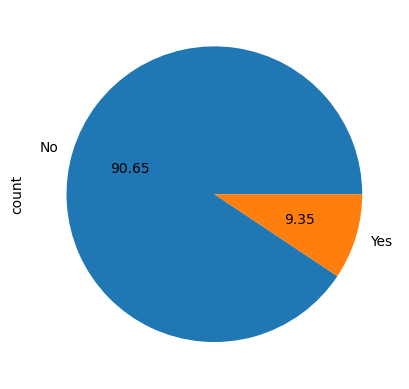

In [23]:
labels['PotentialFraud'].value_counts().plot.pie(autopct='%.2f')

## **3. Data Preprocessing**

### 3.1. Merge Data

#### 3.1.1. Union Inpatient and Outpatient

In [24]:
inpatient['is_ip'] = 1
outpatient['is_ip'] = 0

In [25]:
claims = pd.concat([inpatient, outpatient], ignore_index=True)
print(claims.shape)

(558211, 31)


In [26]:
import gc 
del inpatient, outpatient
gc.collect()

1420

#### 3.1.2. Drop Claims without Attending Physician

In [27]:
claims['AttendingPhysician'].isnull().sum()

np.int64(1508)

In [28]:
claims = claims[claims['AttendingPhysician'].notna()].reset_index(drop=True)
claims.shape

(556703, 31)

#### 3.1.3. Merge Beneficiary and Labels

In [29]:
claims = claims.merge(beneficiary, on='BeneID', how='left')
claims = claims.merge(labels, on='Provider', how='inner')

In [30]:
claims['label'] = (claims['PotentialFraud'] == 'Yes').astype(int)
claims.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,...,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt,PotentialFraud,label
0,BENE11001,CLM46614,2009-04-12,2009-04-18,PRV55912,26000,PHY390922,NaN,NaN,2009-04-12,...,1,2,1,1,36000,3204,60,70,Yes,1
1,BENE11001,CLM66048,2009-08-31,2009-09-02,PRV55907,5000,PHY318495,PHY318495,NaN,2009-08-31,...,1,2,1,1,36000,3204,60,70,No,0
2,BENE11001,CLM68358,2009-09-17,2009-09-20,PRV56046,5000,PHY372395,NaN,PHY324689,2009-09-17,...,1,2,1,1,36000,3204,60,70,No,0
3,BENE11011,CLM38412,2009-02-14,2009-02-22,PRV52405,5000,PHY369659,PHY392961,PHY349768,2009-02-14,...,2,2,1,1,5000,1068,250,320,No,0
4,BENE11014,CLM63689,2009-08-13,2009-08-30,PRV56614,10000,PHY379376,PHY398258,NaN,2009-08-13,...,1,2,2,2,21260,2136,120,100,No,0


### 3.2. Claim Features

In [32]:
date_cols = ['ClaimStartDt', 'ClaimEndDt', 'AdmissionDt', 'DischargeDt', 'DOB']
for col in date_cols:
    claims[col] = pd.to_datetime(claims[col], errors='coerce')

In [33]:
diag_cols = [f'ClmDiagnosisCode_{i}' for i in range(1, 11)]
proc_cols = [f'ClmProcedureCode_{i}' for i in range(1, 7)]

claims['claim_days'] = (claims['ClaimEndDt'] - claims['ClaimStartDt']).dt.days.fillna(0)
claims['los'] = (claims['DischargeDt'] - claims['AdmissionDt']).dt.days.fillna(0)    # length of stay (0 for outpatient)
claims['n_diag'] = claims[diag_cols].notna().sum(axis=1)
claims['n_proc'] = claims[proc_cols].notna().sum(axis=1)
claims['n_phys'] = claims[physician_cols].notna().sum(axis=1)
claims['DeductibleAmtPaid'] = claims['DeductibleAmtPaid'].fillna(0)
claims['age'] = ((claims['ClaimStartDt'] - claims['DOB']).dt.days / 365.25).fillna(0)
claims['diag1_code'] = claims['ClmDiagnosisCode_1'].astype(str).str[:3].astype('category').cat.codes

In [34]:
claims[['claim_days', 'los', 'n_diag', 'n_proc', 'n_phys', 'age']].describe()

,claim_days,los,n_diag,n_proc,n_phys,age
count,556703.000000,556703.000000,556703.000000,556703.000000,556703.000000,556703.000000
mean,1.727918,0.410364,3.011345,0.053585,1.564315,73.297201
std,4.905114,2.111037,2.448488,0.280638,0.635716,13.017061
min,0.000000,0.000000,0.000000,0.000000,1.000000,25.092402
25%,0.000000,0.000000,1.000000,0.000000,1.000000,67.542779
50%,0.000000,0.000000,2.000000,0.000000,1.000000,74.203970
75%,0.000000,0.000000,4.000000,0.000000,2.000000,81.954825
max,36.000000,35.000000,10.000000,5.000000,3.000000,100.993840


### 3.3. Beneficiary Features

In [35]:
chronic_cols = [c for c in claims.columns if c.startswith('ChronicCond_')]
chronic_cols

['ChronicCond_Alzheimer',
 'ChronicCond_Heartfailure',
 'ChronicCond_KidneyDisease',
 'ChronicCond_Cancer',
 'ChronicCond_ObstrPulmonary',
 'ChronicCond_Depression',
 'ChronicCond_Diabetes',
 'ChronicCond_IschemicHeart',
 'ChronicCond_Osteoporasis',
 'ChronicCond_rheumatoidarthritis',
 'ChronicCond_stroke']

In [36]:
claims['gender'] = (claims['Gender'] == 2).astype(int)
claims['renal'] = (claims['RenalDiseaseIndicator'] == 'Y').astype(int)
claims['is_dead'] = claims['DOD'].notna().astype(int)

for col in chronic_cols:
    claims[col] = (claims[col] == 1).astype(int)     # 1 = yes, 2 = no  -->  1 / 0

claims['county_key'] = claims['State'] * 1000 + claims['County']   # county codes repeat across states

race = pd.get_dummies(claims['Race'], prefix='race', dtype=int)
race_cols = list(race.columns)
claims = pd.concat([claims, race], axis=1)

### 3.4. Give Index Number

In [38]:
claims['prov_idx'], provider_names = pd.factorize(claims['Provider'], sort=True)
claims['bene_idx'], bene_names = pd.factorize(claims['BeneID'], sort=True)

N_PROV = len(provider_names)
N_BENE = len(bene_names)

In [39]:
N_PROV, N_BENE, len(claims)

(5410, 138478, 556703)

### 3.5. Drop Columns

In [40]:
drop_cols = diag_cols + proc_cols + ['ClmAdmitDiagnosisCode', 'DiagnosisGroupCode', 'ClaimStartDt',
             'ClaimEndDt', 'AdmissionDt', 'DischargeDt', 'DOB', 'DOD', 'PotentialFraud']

In [41]:
claims = claims.drop(columns=drop_cols)
print(claims.shape)

(556703, 49)


## **4. Feature Engineering**

### 4.1. X_mean (Average Features)

In [42]:
amount_cols = ['IPAnnualReimbursementAmt', 'IPAnnualDeductibleAmt', 'OPAnnualReimbursementAmt', 'OPAnnualDeductibleAmt']
month_cols = ['NoOfMonths_PartACov', 'NoOfMonths_PartBCov']

g = claims.groupby('prov_idx')

X_mean_df = pd.DataFrame({
    'reimb_mean': g['InscClaimAmtReimbursed'].mean(),
    'reimb_std': g['InscClaimAmtReimbursed'].std().fillna(0),
    'ded_mean': g['DeductibleAmtPaid'].mean(),
    'claim_days_mean': g['claim_days'].mean(),
    'los_mean': g['los'].mean(),
    'n_diag_mean': g['n_diag'].mean(),
    'n_proc_mean': g['n_proc'].mean(),
    'n_phys_mean': g['n_phys'].mean(),
    'age_mean': g['age'].mean(),
    'male_frac': g['gender'].mean(),
    'dead_frac': g['is_dead'].mean(),
    'renal_frac': g['renal'].mean(),
    'ip_ratio': g['is_ip'].mean(),
})
for col in chronic_cols + amount_cols + month_cols:
    X_mean_df['mean_' + col] = g[col].mean()

X_MEAN = list(X_mean_df.columns)
X_mean_df.head()

,reimb_mean,reimb_std,ded_mean,claim_days_mean,los_mean,n_diag_mean,n_proc_mean,n_phys_mean,age_mean,male_frac,...,mean_ChronicCond_IschemicHeart,mean_ChronicCond_Osteoporasis,mean_ChronicCond_rheumatoidarthritis,mean_ChronicCond_stroke,mean_IPAnnualReimbursementAmt,mean_IPAnnualDeductibleAmt,mean_OPAnnualReimbursementAmt,mean_OPAnnualDeductibleAmt,mean_NoOfMonths_PartACov,mean_NoOfMonths_PartBCov
prov_idx,,,,,,,,,,,,,,,,,,,,,
0,4185.600000,10796.091144,213.600000,1.440000,1.000000,3.200000,0.120000,1.600000,78.209446,0.640000,...,0.920000,0.240000,0.320000,0.240000,17606.000000,897.120000,2615.200000,463.920000,12.000000,12.000000
1,4588.409091,7309.794729,502.166667,3.674242,2.424242,5.250000,0.363636,1.530303,69.539792,0.590909,...,0.848485,0.250000,0.287879,0.090909,7568.181818,931.424242,2678.181818,737.121212,11.818182,11.871212
2,350.134228,689.963754,2.080537,1.429530,0.000000,2.583893,0.000000,1.604027,71.738434,0.691275,...,0.724832,0.328859,0.308725,0.114094,4351.879195,434.953020,2194.899329,622.751678,11.865772,11.959732
3,239.303525,488.586017,3.181427,1.073087,0.000000,2.588134,0.000000,1.601892,70.081287,0.560619,...,0.767842,0.294927,0.283749,0.105761,3625.924334,378.895959,2096.870163,631.937231,11.907137,11.939811
4,468.194444,1433.769116,45.333333,0.958333,0.222222,2.986111,0.013889,1.527778,68.790174,0.527778,...,0.708333,0.291667,0.305556,0.166667,3050.000000,445.000000,1729.722222,469.722222,11.833333,11.833333


### 4.2. X_vol (Volume Features)

In [43]:
phys_long = claims[['prov_idx'] + physician_cols].melt(id_vars='prov_idx', value_name='phys').dropna()
n_physicians = phys_long.drop_duplicates(['prov_idx', 'phys']).groupby('prov_idx').size()

X_vol_df = pd.DataFrame({
    'n_claims': g.size(),
    'n_ip': g['is_ip'].sum(),
    'n_bene': g['bene_idx'].nunique(),
    'n_physicians': n_physicians,
    'reimb_sum': g['InscClaimAmtReimbursed'].sum(),
    'reimb_max': g['InscClaimAmtReimbursed'].max(),
    'state_nunique': g['State'].nunique(),
    'county_nunique': g['county_key'].nunique(),
})
X_vol_df['claims_per_bene'] = X_vol_df['n_claims'] / X_vol_df['n_bene']
X_vol_df['reimb_per_bene'] = X_vol_df['reimb_sum'] / X_vol_df['n_bene']

X_VOL = list(X_vol_df.columns)
X_vol_df.head()

,n_claims,n_ip,n_bene,n_physicians,reimb_sum,reimb_max,state_nunique,county_nunique,claims_per_bene,reimb_per_bene
prov_idx,,,,,,,,,,
0,25,5,24,19,104640,42000,1,7,1.041667,4360.000000
1,132,62,117,51,605670,57000,3,28,1.128205,5176.666667
2,149,0,138,48,52170,3300,9,33,1.079710,378.043478
3,1163,0,495,7,278310,4080,4,27,2.349495,562.242424
4,72,3,58,11,33710,10000,2,6,1.241379,581.206897


### 4.3. Provider Table

In [44]:
providers = pd.concat([X_mean_df, X_vol_df], axis=1).fillna(0)
providers['label'] = g['label'].first()

y = providers['label'].values
n_claims_per_prov = providers['n_claims'].values
providers.head()

,reimb_mean,reimb_std,ded_mean,claim_days_mean,los_mean,n_diag_mean,n_proc_mean,n_phys_mean,age_mean,male_frac,...,n_ip,n_bene,n_physicians,reimb_sum,reimb_max,state_nunique,county_nunique,claims_per_bene,reimb_per_bene,label
prov_idx,,,,,,,,,,,,,,,,,,,,,
0,4185.600000,10796.091144,213.600000,1.440000,1.000000,3.200000,0.120000,1.600000,78.209446,0.640000,...,5,24,19,104640,42000,1,7,1.041667,4360.000000,0
1,4588.409091,7309.794729,502.166667,3.674242,2.424242,5.250000,0.363636,1.530303,69.539792,0.590909,...,62,117,51,605670,57000,3,28,1.128205,5176.666667,1
2,350.134228,689.963754,2.080537,1.429530,0.000000,2.583893,0.000000,1.604027,71.738434,0.691275,...,0,138,48,52170,3300,9,33,1.079710,378.043478,0
3,239.303525,488.586017,3.181427,1.073087,0.000000,2.588134,0.000000,1.601892,70.081287,0.560619,...,0,495,7,278310,4080,4,27,2.349495,562.242424,1
4,468.194444,1433.769116,45.333333,0.958333,0.222222,2.986111,0.013889,1.527778,68.790174,0.527778,...,3,58,11,33710,10000,2,6,1.241379,581.206897,0


In [45]:
len(X_MEAN), len(X_VOL)

(30, 10)

In [46]:
y.sum(), f'({y.mean():.2%})'

(np.int64(506), '(9.35%)')

### 4.4. Claim Attributes (GNN Edges)

In [47]:
EDGE_ATTR_COLS = ['InscClaimAmtReimbursed', 'DeductibleAmtPaid', 'claim_days', 'los',
                  'is_ip', 'n_diag', 'n_proc', 'n_phys']

In [48]:
claim_prov = claims['prov_idx'].values
claim_bene = claims['bene_idx'].values
claim_attr = claims[EDGE_ATTR_COLS].values.astype(np.float32)
claim_attr.shape

(556703, 8)

### 4.5. Patient (Beneficiary Features)

In [49]:
from sklearn.preprocessing import StandardScaler

bene_feat_cols = ['gender', 'renal', 'is_dead', 'age'] + chronic_cols + race_cols + amount_cols + month_cols
bene_table = claims.drop_duplicates('bene_idx').sort_values('bene_idx')

X_bene = bene_table[bene_feat_cols].astype(float).values
X_bene = StandardScaler().fit_transform(X_bene).astype(np.float32)

In [50]:
X_bene.shape

(138478, 25)

## **5. Data Split**

In [51]:
from sklearn.model_selection import train_test_split

def make_split(y, seed):
    idx = np.arange(len(y))
    train, rest = train_test_split(idx, test_size=0.4, stratify=y, random_state=seed)
    val, test = train_test_split(rest, test_size=0.5, stratify=y[rest], random_state=seed)
    return {'train': train, 'val': val, 'test': test}

In [54]:
splits = [make_split(y, SEED + s) for s in range(N_SPLITS)]

for s, sp in enumerate(splits):
    print(f"split {s}: train {len(sp['train'])}, val {len(sp['val'])}, test {len(sp['test'])}, "
          f"fraud in test {y[sp['test']].mean():.3f}")

split 0: train 3246, val 1082, test 1082, fraud in test 0.093
split 1: train 3246, val 1082, test 1082, fraud in test 0.093
split 2: train 3246, val 1082, test 1082, fraud in test 0.093
split 3: train 3246, val 1082, test 1082, fraud in test 0.093
split 4: train 3246, val 1082, test 1082, fraud in test 0.093


## **6. Graph Construction and Centrality**

### 6.1. Making Two Bipartite Graphs

In [55]:
import scipy.sparse as sp

def bipartite_adjacency(prov_idx, other_idx, n_prov, n_other):
    # node 0..n_prov-1 = providers, node n_prov.. = the other side
    n = n_prov + n_other
    A = sp.coo_matrix((np.ones(len(prov_idx)), (prov_idx, n_prov + other_idx)), shape=(n, n))
    A = (A + A.T).tocsr()
    A.data[:] = 1.0
    return A

In [56]:
pb_pairs = claims[['prov_idx', 'bene_idx']].drop_duplicates()
A_pb = bipartite_adjacency(pb_pairs['prov_idx'].values, pb_pairs['bene_idx'].values, N_PROV, N_BENE)
print('provider-patient graph:', A_pb.shape[0], 'nodes,', A_pb.nnz // 2, 'edges')

provider-patient graph: 143888 nodes, 362556 edges


In [57]:
ph_pairs = phys_long.drop_duplicates(['prov_idx', 'phys']).copy()
ph_pairs['phys_idx'] = pd.factorize(ph_pairs['phys'])[0]
n_phys_nodes = ph_pairs['phys_idx'].max() + 1

A_ph = bipartite_adjacency(ph_pairs['prov_idx'].values, ph_pairs['phys_idx'].values, N_PROV, n_phys_nodes)
print('provider-physician graph:', A_ph.shape[0], 'nodes,', A_ph.nnz // 2, 'edges')

provider-physician graph: 106144 nodes, 109336 edges


### 6.2. Centrality Functions

In [58]:
import networkx as nx
from scipy.sparse.linalg import eigsh
from scipy.sparse.csgraph import dijkstra

def closeness_estimate(A, n_prov, n_pivots=256, seed=0):
    pivots = np.random.default_rng(seed).choice(A.shape[0], n_pivots, replace=False)
    dist = dijkstra(A, directed=False, unweighted=True, indices=pivots)[:, :n_prov]
    reach = np.isfinite(dist)
    total = np.where(reach, dist, 0).sum(axis=0)
    n_reach = reach.sum(axis=0)
    # (1 / average distance) x (share of nodes reached), like networkx closeness
    return np.where(total > 0, (n_reach / np.maximum(total, 1)) * (n_reach / n_pivots), 0)

In [59]:
def centrality(A, n_prov, prefix):
    degree = np.asarray(A.sum(axis=1)).ravel()

    pagerank = nx.pagerank(nx.from_scipy_sparse_array(A), alpha=0.85)
    pagerank = np.array([pagerank[i] for i in range(A.shape[0])]) * A.shape[0]

    _, vec = eigsh(A.astype(float), k=1, which='LA')
    eigen = np.abs(vec[:, 0]) * np.sqrt(A.shape[0])

    return pd.DataFrame({
        prefix + '_degree': degree[:n_prov],
        prefix + '_eigen': eigen[:n_prov],
        prefix + '_closeness': closeness_estimate(A, n_prov),
        prefix + '_pagerank': pagerank[:n_prov],
    })

### 6.3. Compute Centrality (X_cent)

In [60]:
cent_file = RESULT_DIR + 'centrality.csv'

if os.path.exists(cent_file):
    X_cent_df = pd.read_csv(cent_file)
else:
    X_cent_df = pd.concat([centrality(A_pb, N_PROV, 'pb'), centrality(A_ph, N_PROV, 'ph')], axis=1)
    X_cent_df.to_csv(cent_file, index=False)

X_CENT = list(X_cent_df.columns)
X_CENT_NO_DEGREE = [c for c in X_CENT if not c.endswith('_degree')]
providers = pd.concat([providers, X_cent_df.set_index(providers.index)], axis=1)
X_cent_df.describe()
# centrality is saved to a file because it takes a few minutes

,pb_degree,pb_eigen,pb_closeness,pb_pagerank,ph_degree,ph_eigen,ph_closeness,ph_pagerank
count,5410.000000,5.410000e+03,5410.000000,5410.000000,5410.000000,5.410000e+03,5410.000000,5410.000000
mean,67.015896,3.454530e-01,0.185241,11.462050,20.209982,4.963053e-02,0.032857,8.661356
std,142.509278,3.630625e+00,0.026582,24.379628,36.228322,3.131985e+00,0.027225,15.004938
min,1.000000,9.770950e-17,0.000000,0.272481,1.000000,1.627269e-18,0.000000,0.438138
25%,8.000000,2.938105e-03,0.168754,1.650708,2.000000,5.304078e-15,0.000000,1.434811
50%,25.000000,2.204088e-02,0.187821,4.357538,7.000000,1.275195e-14,0.046198,3.306272
75%,64.000000,1.777079e-01,0.201734,10.829775,23.000000,4.152332e-12,0.055588,9.829169
max,2852.000000,2.322680e+02,0.289921,552.360198,735.000000,2.297678e+02,0.083694,297.741527


### 6.4. Is Centrality just Volume?

In [61]:
from scipy.stats import spearmanr

volume = {'log_n_claims': np.log1p(providers['n_claims']), 'log_n_bene': np.log1p(providers['n_bene'])}
C1 = pd.DataFrame({v: [spearmanr(providers[c], volume[v]).correlation for c in X_CENT] for v in volume}, index=X_CENT)
C1.round(3)

,log_n_claims,log_n_bene
pb_degree,0.982,1.000
pb_eigen,0.693,0.758
pb_closeness,0.729,0.798
pb_pagerank,0.987,0.994
ph_degree,0.626,0.672
ph_eigen,0.356,0.381
ph_closeness,0.370,0.392
ph_pagerank,0.621,0.667


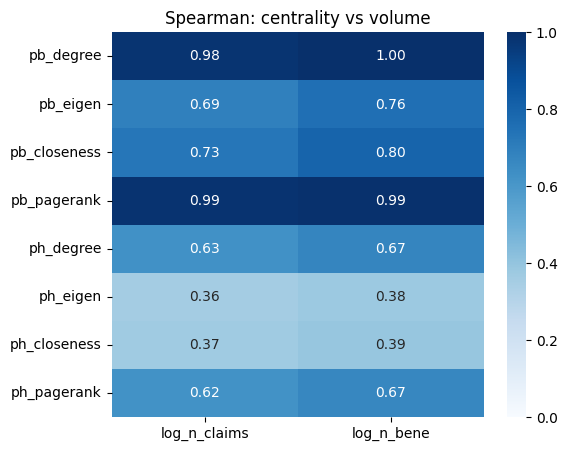

In [62]:
plt.figure(figsize=(6, 5))
sns.heatmap(C1, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Spearman: centrality vs volume')
plt.show()

### 6.5. PROJECT_PROVIDER Edges

In [63]:
def project_provider_edges(cols):
    pairs = claims[['prov_idx'] + cols].melt(id_vars='prov_idx', value_name='phys').dropna()
    pairs = pairs.drop_duplicates(['prov_idx', 'phys'])
    pairs['phys_idx'] = pd.factorize(pairs['phys'])[0]
    B = sp.csr_matrix((np.ones(len(pairs)), (pairs['prov_idx'], pairs['phys_idx'])))
    P = (B @ B.T).tocoo()
    keep = P.row != P.col
    return np.vstack([P.row[keep], P.col[keep]])     # both directions

In [65]:
rows = []
for name, cols in {'all 3 physician columns': physician_cols, 'attending only': ['AttendingPhysician']}.items():
    e = project_provider_edges(cols)
    row = {'definition': name}
    for part in ['train', 'val', 'test']:
        ids = splits[0][part]
        row[part] = int((np.isin(e[0], ids) & np.isin(e[1], ids)).sum())
    rows.append(row)
rows.append({'definition': 'Yoo et al. (Table 3)', 'train': 3486, 'val': 342, 'test': 308})
pd.DataFrame(rows)

,definition,train,val,test
0,all 3 physician columns,4562,474,500
1,attending only,3456,318,378
2,Yoo et al. (Table 3),3486,342,308


In [66]:
project_edges = project_provider_edges(['AttendingPhysician'])
print('PROJECT_PROVIDER edges (directed):', project_edges.shape[1])

PROJECT_PROVIDER edges (directed): 9380


### 6.6. Do Fraud Providers Connect to Fraud Providers?

In [67]:
src, dst = project_edges
print(f'P(neighbour is fraud | provider is fraud) = {y[dst][y[src] == 1].mean():.3f}')
print(f'base fraud rate = {y.mean():.3f}')

P(neighbour is fraud | provider is fraud) = 0.186
base fraud rate = 0.094


## **7. Evaluation Functions**

In [68]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

def best_threshold(y_true, prob):
    candidates = np.unique(np.quantile(prob, np.linspace(0.01, 0.99, 99)))
    f1s = [f1_score(y_true, prob >= t) for t in candidates]
    return candidates[np.argmax(f1s)]

In [69]:
def get_metrics(y_true, prob, threshold, weight=None):
    pred = (prob >= threshold).astype(int)
    return {
        'precision': precision_score(y_true, pred, sample_weight=weight, zero_division=0),
        'recall': recall_score(y_true, pred, sample_weight=weight, zero_division=0),
        'f1': f1_score(y_true, pred, sample_weight=weight, zero_division=0),
        'auroc': roc_auc_score(y_true, prob, sample_weight=weight),
        'auprc': average_precision_score(y_true, prob, sample_weight=weight),
    }

In [70]:
def evaluate(prob, split):
    val, test = split['val'], split['test']
    threshold = best_threshold(y[val], prob[val])

    fair = get_metrics(y[test], prob[test], threshold)
    yoo_like = get_metrics(y[test], prob[test], 0.5, weight=n_claims_per_prov[test])   # claim level, 0.5

    result = {'threshold': threshold}
    result.update({'fair_' + k: v for k, v in fair.items()})
    result.update({'yoo_' + k: v for k, v in yoo_like.items()})
    return result

In [71]:
RESULT_FILE = RESULT_DIR + 'results.csv'

def save_result(row):
    new = pd.DataFrame([row])
    if os.path.exists(RESULT_FILE):
        old = pd.read_csv(RESULT_FILE)
        old = old[old['run_name'] != row['run_name']]       # replace old result of the same run
        new = pd.concat([old, new], ignore_index=True)
    new.to_csv(RESULT_FILE, index=False)

## **8. Machine Learning Baselines**

### 8.1. Feature Sets

In [72]:
FEATURE_SETS = {
    'M0': X_MEAN,
    'M1': X_MEAN + X_CENT,
    'M1b': X_MEAN + X_CENT_NO_DEGREE,
    'M2': X_MEAN + X_VOL,
    'M3': X_MEAN + X_VOL + X_CENT,
}

### 8.2. Models

In [73]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [74]:
def get_ml_model(name, pos_weight, seed=0):
    scaler = QuantileTransformer(n_quantiles=1000, output_distribution='normal', random_state=0)
    if name == 'LR':
        return make_pipeline(scaler, LogisticRegression(max_iter=3000, class_weight='balanced'))
    if name == 'RF':
        return RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', n_jobs=-1, random_state=seed)
    if name == 'XGB':
        return XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.08, scale_pos_weight=pos_weight,
                             eval_metric='logloss', n_jobs=-1, random_state=seed)
    if name == 'LGBM':
        return LGBMClassifier(n_estimators=300, learning_rate=0.08, scale_pos_weight=pos_weight,
                              n_jobs=-1, random_state=seed, verbose=-1)
    if name == 'MLP':
        return make_pipeline(scaler, MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True,
                                                   max_iter=300, random_state=seed))

### 8.3. Train ML Models in Provider Level

In [75]:
def run_ml(feature_set, model_name, split_id):
    split = splits[split_id]
    train = split['train']
    X = providers[FEATURE_SETS[feature_set]].values

    pos_weight = (y[train] == 0).sum() / (y[train] == 1).sum()
    model = get_ml_model(model_name, pos_weight)
    model.fit(X[train], y[train])
    prob = model.predict_proba(X)[:, 1]

    row = {'run_name': f'{feature_set}:{model_name}_s{split_id}', 'model': f'{feature_set}:{model_name}',
           'family': 'ML', 'split': split_id, 'seed': 0}
    row.update(evaluate(prob, split))
    save_result(row)
    return row

In [76]:
ml_rows = []
for split_id in range(N_SPLITS):
    for feature_set in FEATURE_SETS:
        for model_name in ML_MODELS:
            ml_rows.append(run_ml(feature_set, model_name, split_id))

ml_results = pd.DataFrame(ml_rows)
ml_results.groupby('model')[['fair_f1', 'fair_auprc', 'fair_auroc', 'yoo_f1']].mean().sort_values('fair_auprc', ascending=False).round(3)

KeyboardInterrupt: 